In [1]:
import sys

sys.path.append("..")

from analysis.utils import get_runs_data, show_config_differences
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from IPython.display import Markdown, display

sns.set_style(style="darkgrid")

In [2]:
# Helper functions

def format_dataset_table_html(df):
    """Format dataset configuration table with grouped column headers."""
    from IPython.display import HTML
    
    html = """
    <style>
        .dataset-table {
            border-collapse: collapse;
            margin: 20px 0;
            font-size: 14px;
            font-family: Arial, sans-serif;
        }
        .dataset-table th {
            background-color: #f2f2f2;
            border: 1px solid #ddd;
            padding: 8px;
            text-align: center;
            font-weight: bold;
        }
        .dataset-table td {
            border: 1px solid #ddd;
            padding: 8px;
            text-align: center;
        }
        .dataset-table tr:nth-child(even) {
            background-color: #f9f9f9;
        }
    </style>
    <table class="dataset-table">
        <thead>
            <tr>
                <th rowspan="2">Dataset</th>
                <th colspan="3">Prefix</th>
                <th colspan="3">Suffix 1</th>
                <th colspan="3">Suffix 2</th>
                <th rowspan="2">Total length</th>
                <th rowspan="2">Total bits</th>
            </tr>
            <tr>
                <th>vocab</th>
                <th>length</th>
                <th>bits</th>
                <th>vocab</th>
                <th>length</th>
                <th>bits</th>
                <th>vocab</th>
                <th>length</th>
                <th>bits</th>
            </tr>
        </thead>
        <tbody>
    """
    
    for idx, row in df.iterrows():
        html += "            <tr>\n"
        html += f"                <td>{row['Dataset']}</td>\n"
        html += f"                <td>{int(row['prefix_vocab_size'])}</td>\n"
        html += f"                <td>{int(row['prefix_length'])}</td>\n"
        html += f"                <td>{int(round(row['prefix_bits']))}</td>\n"
        html += f"                <td>{int(row['suffix1_vocab_size'])}</td>\n"
        html += f"                <td>{int(row['suffix1_length'])}</td>\n"
        html += f"                <td>{int(round(row['suffix1_bits']))}</td>\n"
        html += f"                <td>{int(row['suffix2_vocab_size'])}</td>\n"
        html += f"                <td>{int(row['suffix2_length'])}</td>\n"
        html += f"                <td>{int(round(row['suffix2_bits']))}</td>\n"
        html += f"                <td>{int(row['total_length'])}</td>\n"
        html += f"                <td>{int(round(row['total_bits']))}</td>\n"
        html += "            </tr>\n"
    
    html += """
        </tbody>
    </table>
    """
    
    return HTML(html)

def show_dataset_configurations(data) -> pd.DataFrame:
    dataset_cols = [
        'cfg.dataset.prefix_vocab_size',
        'cfg.dataset.prefix_length',
        'cfg.dataset.suffix1_vocab_size',
        'cfg.dataset.suffix1_length',
        'cfg.dataset.suffix2_vocab_size',
        'cfg.dataset.suffix2_length',
    ]

    df = data.groupby("_run_id")[dataset_cols].first()
    df.columns = df.columns.str.replace('cfg.dataset.', '')

    # compute information content in bits per region
    import numpy as np
    df['prefix_bits'] = df['prefix_length'] * np.log2(df['prefix_vocab_size'])
    df['suffix1_bits'] = df['suffix1_length'] * np.log2(df['suffix1_vocab_size'])
    df['suffix2_bits'] = df['suffix2_length'] * np.log2(df['suffix2_vocab_size'])
    df['total_bits'] = df['prefix_bits'] + df['suffix1_bits'] + df['suffix2_bits']
    df['total_length'] = df['prefix_length'] + df['suffix1_length'] + df['suffix2_length']

    # Reorder columns in the correct sequence
    df = df[[
        'prefix_vocab_size', 'prefix_length', 'prefix_bits',
        'suffix1_vocab_size', 'suffix1_length', 'suffix1_bits',
        'suffix2_vocab_size', 'suffix2_length', 'suffix2_bits',
        'total_length', 'total_bits'
    ]]

    # Add dataset labels (A, B, C, etc.)
    df.insert(0, 'Dataset', [chr(65 + i) for i in range(len(df))])
    df = df.reset_index(drop=True)

    return df

def plot_metric(data, metric_name, ylabel, groupby_col, groupby_name):
    groups = data.groupby(groupby_col)[[metric_name, "train/global_step"]]
    for (groupby_col), group in groups:
        steps = group["train/global_step"].to_list()
        exact_match = group[metric_name].to_list()
        label = f"{groupby_name}: {groupby_col}"
        plt.plot(steps, exact_match, label=label, linewidth=2)

    plt.xlabel("Step", fontsize=18)
    plt.ylabel(ylabel, fontsize=18)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(fontsize=14)
    plt.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        fontsize=16,
        ncol=1,
        frameon=False,
    )
    plt.tight_layout()
    plt.show()

# Interference in prefix

Disambiguating content (or information content) differs in the prefix but remains the same in `Suffix-1` region where the exact match evaluation is done. `Suffix-2` region maintains iso-information across datasets.

In [3]:
data = get_runs_data(
    tag="interference-prefix",
    project="memorization",
    metrics=[
        "train/exact_match_repeated",
        "train/loss_total_suffix2",
        "train/loss_total_suffix1",
        "train/loss_total_prefix",
        "train/loss_total",
    ],
)
show_config_differences(data)

Found 2 runs with tag 'interference-prefix'


,cfg.dataset.prefix_vocab_size,cfg.dataset.suffix2_vocab_size
_run_id,,
an03a0bs,16,512
pzmib310,1024,8


In [4]:
df = show_dataset_configurations(data)
display(format_dataset_table_html(df))

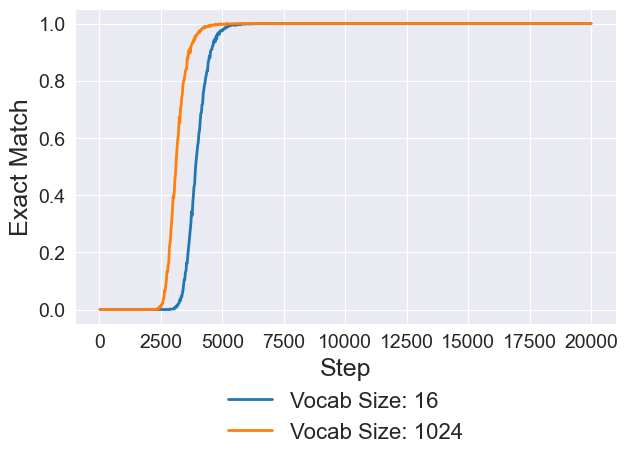

In [5]:
plot_metric(data, "train/exact_match_repeated", "Exact Match", groupby_col="cfg.dataset.prefix_vocab_size", groupby_name="Vocab Size")

# Interference in Suffix-1

Disambiguating content (or information content) in the prefix remains the same but it varies in `Suffix-1` region where the exact match evaluation is done.
`Suffix-2` region maintains iso-information across datasets.

In [6]:
data = get_runs_data(
    tag="interference-suffix1",
    project="memorization",
    metrics=[
        "train/exact_match_repeated",
        "train/loss_total_suffix2",
        "train/loss_total_suffix1",
        "train/loss_total_prefix",
        "train/loss_total",
    ],
)
show_config_differences(data)

Found 2 runs with tag 'interference-suffix1'


,cfg.dataset.suffix1_vocab_size,cfg.dataset.suffix2_vocab_size
_run_id,,
0nb31bjk,1024,8
bsb6ecf4,16,512
